In [1]:
import sys, time
sys.path.append("../src")
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from xgboost import XGBRegressor

from donnees import charger_raca, nettoyer_raca, reechantillonner_raca
from evaluation import scores_regression
from sequences import fenetres, entrainer_reseau, predire, ReseauGRU

serie = reechantillonner_raca(nettoyer_raca(charger_raca()))
dl = serie[serie["application"] == "Download"].copy()
dl["debit"] = dl["DL_bitrate"] / 1000
VARIABLES = ["debit", "RSRP", "RSRQ", "SNR", "CQI"]

traces = sorted(dl["trace"].unique())
np.random.default_rng(0).shuffle(traces)
plis = [traces[i:i + 3] for i in range(0, 21, 3)]       # 7 plis de 3 traces
for k, p in enumerate(plis):
    print("pli", k, ":", round(dl[dl["trace"].isin(p)]["debit"].mean(), 1), "Mbit/s en moyenne")

pli 0 : 25.5 Mbit/s en moyenne
pli 1 : 47.5 Mbit/s en moyenne
pli 2 : 59.8 Mbit/s en moyenne
pli 3 : 19.3 Mbit/s en moyenne
pli 4 : 44.8 Mbit/s en moyenne
pli 5 : 45.9 Mbit/s en moyenne
pli 6 : 49.3 Mbit/s en moyenne


In [2]:
aplatir = lambda X: X.reshape(len(X), -1)

def validation_croisee(W, horizons, avec_gru=True):
    lignes, debut = [], time.time()
    for k in range(7):
        test, val = plis[k], plis[(k + 1) % 7]            # % 7 : après le pli 6, on revient au pli 0
        entr = [t for t in traces if t not in test + val]
        e = dl[dl["trace"].isin(entr)]
        moy, ect = e[VARIABLES].mean(), e[VARIABLES].std()   # recalculées à chaque pli
        for h in horizons:
            Xe, ye, _, _ = fenetres(e, VARIABLES, moy, ect, W=W, h=h)
            Xv, yv, _, _ = fenetres(dl[dl["trace"].isin(val)], VARIABLES, moy, ect, W=W, h=h)
            Xt, yt, evt, pt = fenetres(dl[dl["trace"].isin(test)], VARIABLES, moy, ect, W=W, h=h)
            xgb = XGBRegressor(n_estimators=1000, learning_rate=0.05, max_depth=6, n_jobs=-1,
                               random_state=0, early_stopping_rounds=30)
            xgb.fit(aplatir(Xe), ye, eval_set=[(aplatir(Xv), yv)], verbose=False)
            predictions = [("persistance", pt), ("xgb", xgb.predict(aplatir(Xt)))]
            if avec_gru:
                torch.manual_seed(0)
                gru, _ = entrainer_reseau(ReseauGRU(Xe.shape[2]), Xe, ye, Xv, yv)
                predictions.append(("gru", predire(gru, Xt)))
            for nom, p in predictions:
                lignes.append({"W": W, "pli": k, "horizon": h, "modele": nom,
                               **scores_regression(yt[evt], p[evt])})
        print(f"pli {k} terminé ({time.time() - debut:.0f} s)")
    return pd.DataFrame(lignes)

cv10 = validation_croisee(10, [1, 5, 10])
cv10.to_csv("../results/tables/raca_cv_W10.csv", index=False)

60 époques, meilleure à l'époque 55, 146 s
37 époques, meilleure à l'époque 29, 60 s
39 époques, meilleure à l'époque 31, 67 s
pli 0 terminé (293 s)
40 époques, meilleure à l'époque 32, 54 s
25 époques, meilleure à l'époque 17, 36 s
19 époques, meilleure à l'époque 11, 27 s
pli 1 terminé (414 s)
31 époques, meilleure à l'époque 23, 46 s
44 époques, meilleure à l'époque 36, 69 s
14 époques, meilleure à l'époque 6, 26 s
pli 2 terminé (559 s)
29 époques, meilleure à l'époque 21, 54 s
32 époques, meilleure à l'époque 24, 62 s
29 époques, meilleure à l'époque 21, 60 s
pli 3 terminé (741 s)
31 époques, meilleure à l'époque 23, 68 s
27 époques, meilleure à l'époque 19, 64 s
19 époques, meilleure à l'époque 11, 36 s
pli 4 terminé (917 s)
46 époques, meilleure à l'époque 38, 82 s
46 époques, meilleure à l'époque 38, 92 s
21 époques, meilleure à l'époque 13, 38 s
pli 5 terminé (1135 s)
42 époques, meilleure à l'époque 34, 91 s
15 époques, meilleure à l'époque 7, 30 s
33 époques, meilleure à l'ép

modele         gru  persistance    xgb
horizon pli                           
1       0    0.845        0.783  0.840
        1    0.809        0.710  0.804
        2    0.811        0.712  0.810
        3    0.744        0.687  0.745
        4    0.825        0.748  0.819
        5    0.773        0.694  0.771
        6    0.821        0.746  0.802
5       0    0.641        0.244  0.643
        1    0.438       -0.191  0.500
        2    0.513        0.035  0.568
        3    0.307       -0.134  0.368
        4    0.598        0.135  0.605
        5    0.362       -0.132  0.429
        6    0.441       -0.083  0.500
10      0    0.616        0.199  0.596
        1    0.319       -0.333  0.371
        2    0.423       -0.109  0.464
        3    0.151       -0.393  0.287
        4    0.528        0.042  0.501
        5    0.308       -0.231  0.346
        6    0.372       -0.219  0.370
modele     gru        persistance           xgb       
          mean    std        mean    std   mean 

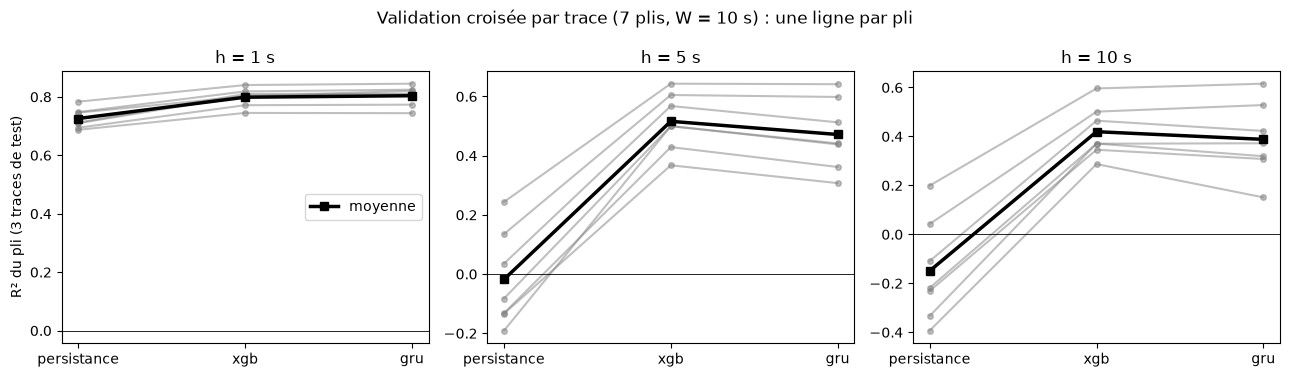

In [3]:
r2 = cv10.pivot_table(index=["horizon", "pli"], columns="modele", values="R2")
print(r2.round(3))          # le R² de chaque modèle dans chaque pli
print(r2.groupby("horizon").agg(["mean", "std"]).round(3))       # moyenne et écart-type sur les 7 plis

ecart = (r2["xgb"] - r2["gru"]).unstack("pli")                    # comparaison pli par pli
print(ecart.round(3))
print(pd.DataFrame({"écart moyen": ecart.mean(axis=1),
                    "plis où XGBoost gagne": (ecart > 0).sum(axis=1)}).round(3))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, h in zip(axes, [1, 5, 10]):
    d = r2.loc[h]
    for pli, ligne in d.iterrows():                               # une ligne grise par pli
        ax.plot(["persistance", "xgb", "gru"], ligne[["persistance", "xgb", "gru"]],
                color="grey", alpha=0.5, marker="o", ms=4)
    ax.plot(["persistance", "xgb", "gru"], d[["persistance", "xgb", "gru"]].mean(),
            color="black", lw=2.5, marker="s", label="moyenne")
    ax.axhline(0, color="black", lw=0.6); ax.set_title(f"h = {h} s")
axes[0].set_ylabel("R² du pli (3 traces de test)"); axes[0].legend()
fig.suptitle("Validation croisée par trace (7 plis, W = 10 s) : une ligne par pli")
fig.tight_layout()
fig.savefig("../results/figures/raca_cv_W10.png", dpi=150, bbox_inches="tight")
plt.show()

pli 0 terminé (28 s)
pli 1 terminé (49 s)
pli 2 terminé (64 s)
pli 3 terminé (82 s)
pli 4 terminé (99 s)
pli 5 terminé (127 s)
pli 6 terminé (151 s)
pli          0      1      2      3      4      5      6
horizon                                                 
1        0.034  0.068  0.052  0.056  0.054  0.056  0.068
5        0.028  0.019  0.010  0.017  0.032  0.000  0.034
10       0.030  0.002  0.004  0.018  0.033 -0.053  0.029
         R² W=10  R² W=30  gain moyen  plis améliorés
horizon                                              
1          0.799    0.854       0.055               7
5          0.516    0.536       0.020               7
10         0.419    0.428       0.009               6


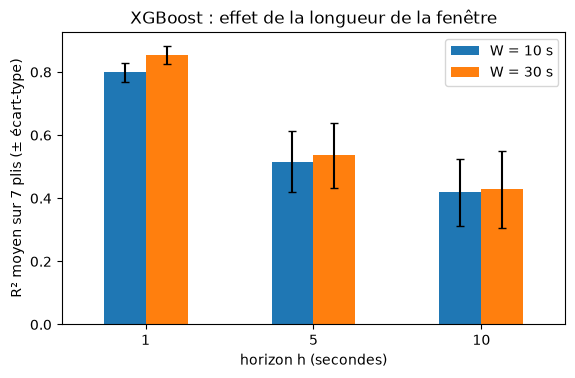

In [4]:
cv30 = validation_croisee(30, [1, 5, 10], avec_gru=False)
cv30.to_csv("../results/tables/raca_cv_W30.csv", index=False)

x10 = cv10[cv10["modele"] == "xgb"].set_index(["horizon", "pli"])["R2"]
x30 = cv30[cv30["modele"] == "xgb"].set_index(["horizon", "pli"])["R2"]
gain = (x30 - x10).unstack("pli")                     # gain de W = 30 dans chaque pli
print(gain.round(3))
print(pd.DataFrame({"R² W=10": x10.groupby("horizon").mean(),
                    "R² W=30": x30.groupby("horizon").mean(),
                    "gain moyen": gain.mean(axis=1),
                    "plis améliorés": (gain > 0).sum(axis=1)}).round(3))

moyennes = pd.DataFrame({"W = 10 s": x10.groupby("horizon").mean(), "W = 30 s": x30.groupby("horizon").mean()})
ecarts = pd.DataFrame({"W = 10 s": x10.groupby("horizon").std(), "W = 30 s": x30.groupby("horizon").std()})
ax = moyennes.plot.bar(rot=0, figsize=(6.5, 3.8), yerr=ecarts, capsize=3)
ax.set_xlabel("horizon h (secondes)"); ax.set_ylabel("R² moyen sur 7 plis (± écart-type)")
ax.set_title("XGBoost : effet de la longueur de la fenêtre")
ax.figure.savefig("../results/figures/raca_cv_fenetre.png", dpi=150, bbox_inches="tight")
plt.show()

In [5]:
groupes = {"entr": traces[:14], "val": traces[14:17], "test": traces[17:]}   # répartition des séances 12-13
e = dl[dl["trace"].isin(groupes["entr"])]
moy, ect = e[VARIABLES].mean(), e[VARIABLES].std()

seance13 = pd.read_csv("../results/tables/raca_reseaux_test.csv")
lignes = []
for h in [1, 5, 10]:
    D = {nom: fenetres(dl[dl["trace"].isin(liste)], VARIABLES, moy, ect, W=30, h=h)
         for nom, liste in groupes.items()}
    Xe, ye, _, _ = D["entr"]
    Xv, yv, _, _ = D["val"]
    Xt, yt, evt, _ = D["test"]
    torch.manual_seed(0)
    gru, _ = entrainer_reseau(ReseauGRU(Xe.shape[2]), Xe, ye, Xv, yv)
    r2_w10 = seance13.query("modele == 'gru' and horizon == @h")["R2"].item()
    lignes.append({"horizon": h, "GRU W=10": r2_w10,
                   "GRU W=30": scores_regression(yt[evt], predire(gru, Xt)[evt])["R2"]})
gru30 = pd.DataFrame(lignes).round(3)
gru30["gain"] = gru30["GRU W=30"] - gru30["GRU W=10"]
gru30.to_csv("../results/tables/raca_gru_W30.csv", index=False)
print(gru30)

43 époques, meilleure à l'époque 35, 231 s
23 époques, meilleure à l'époque 15, 90 s
17 époques, meilleure à l'époque 9, 125 s
   horizon  GRU W=10  GRU W=30   gain
0        1     0.812     0.859  0.047
1        5     0.438     0.498  0.060
2       10     0.355     0.372  0.017
